# 06 · Data Analysis Process — Gathering, Assessing, Cleaning & EDA

Real-world data never arrives clean. This notebook walks the full
**data analysis process** used in industry and in the DSMP sessions:
*gather → assess → clean → explore (EDA)*, with runnable pandas /
seaborn / scikit-learn code for every step, and finishes with an
end-to-end **smartphone case study** (the same dataset used in the
live sessions).

Everything below runs top-to-bottom in a fresh kernel with **no
internet** — every network example has an offline fallback.

> **Note:** this notebook is the pandas-side companion of `03_numpy.ipynb`
> and `04_pandas.ipynb` — it applies those tools to a *process*.

## ▶ Sessions covered

| # | Session | Video |
|---|---------|-------|
| 82 | Session 27 - Data Gathering \| Data Analysis Process | https://www.youtube.com/watch?v=dA6ZksRR6aw |
| 84 | Session 28 - Data Assessing and Cleaning | https://www.youtube.com/watch?v=-HnN8GBINnc |
| 88 | Session on Data Cleaning Case Study - Smartphone dataset | https://www.youtube.com/watch?v=0j_7j3PNSEw |
| 91 | Session 29 - Exploratory Data Analysis | https://www.youtube.com/watch?v=PPEHpg2RixQ |
| 95 | Session 2 on Data Cleaning - Smartphones Dataset | https://www.youtube.com/watch?v=o-8KvsSdDiE |
| 97 | Session on EDA Case Study - Smartphones Dataset | https://www.youtube.com/watch?v=PxRth8xosqY |

In [1]:
%matplotlib inline
import os
import tempfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from io import StringIO
import requests
from bs4 import BeautifulSoup

pd.set_option("display.max_columns", 25)
print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)


pandas 2.3.3 | numpy 2.2.6 | seaborn 0.13.2


---
## 1. The Data Analysis Process — end to end

▶ Session 27 - Data Gathering | Data Analysis Process: https://www.youtube.com/watch?v=dA6ZksRR6aw

```text
 1. Problem         2. Data           3. Data           4. Data
    definition   ──▶  gathering   ──▶  assessment  ──▶  cleaning
    (what & why)     (files, APIs,    (quality +        (missing,
                     scraping, DBs)   tidiness)         dupes, types)
       │                                                       │
       │                                                       ▼
 7. Communication  ◀── 6. Modelling  ◀──────────────────── 5. EDA
    (charts,             (ML / stats,                     (univariate,
     dashboards,          ONLY if needed)                   bivariate,
     reports)                                              multivariate)
```

| # | Step | Question it answers | When it happens | Typical artefact |
|---|------|---------------------|-----------------|------------------|
| 1 | Problem definition | What decision will this analysis drive? | before any code | problem statement |
| 2 | Data gathering | Where does the data live? | once (and on refresh) | raw file / table / API response |
| 3 | Assessing | What is *wrong* with the data? | after gathering, before touching it | list of quality + tidiness issues |
| 4 | Cleaning | How do I fix each issue? | iteratively, once per issue type | analysis-ready DataFrame |
| 5 | EDA | What story does the data tell? | after cleaning; repeated per question | charts + summary tables |
| 6 | Modelling | Can I predict / quantify? | only if the problem needs it | model + metrics |
| 7 | Communication | What should the stakeholder do? | at the end (and at each milestone) | deck / notebook / dashboard |

> **Gotcha:** beginners start coding at step 2 and jump to step 6.
> The professionals spend most of their time in steps **3 and 4** —
> it is estimated that ~60-80% of a data project is data preparation.

**Section notes — process:**

| Step | Owned by | Reversible? |
|---|---|---|
| problem definition | you + stakeholder | cheap to revisit |
| gathering | engineering / you | re-run the pipeline |
| assessing | you (read-only!) | never "fix" during assessment |
| cleaning | you (code, not clicks) | keep the raw data immutable |
| EDA | you | always reproducible from cleaned data |

---
## 2. Data gathering — reading files

▶ Session 27 - Data Gathering | Data Analysis Process: https://www.youtube.com/watch?v=dA6ZksRR6aw

*Gathering* = getting raw data into pandas: flat files, Excel, JSON,
HTML, databases, APIs, scrapes, or building it in memory.

### `pd.read_csv()`
**What it does:** reads a delimited text file (or buffer) into a DataFrame.
**Syntax:** `pd.read_csv(filepath, sep=",", encoding=None, usecols=None, nrows=None, dtype=None, parse_dates=None, na_values=None)`
**Parameters:**
- `filepath_or_buffer` — path / URL / file-like / `StringIO`
- `sep` — field delimiter; `sep=None, engine="python"` sniffs it
- `encoding` — file encoding (default `"utf-8"`; try `"latin-1"` on mojibake/`UnicodeDecodeError`)
- `usecols` — list of columns to keep → less memory, faster read
- `nrows` — read only the first N data rows (peek at huge files)
- `dtype` — dict `{column: dtype}` applied while parsing
- `parse_dates` — columns converted to `datetime64` while reading
- `na_values` — extra strings to treat as `NaN` on top of pandas' defaults
**Returns:** `pd.DataFrame`
**Example:**

In [2]:
CSV_TEXT = """name,age,city,joined,score
Ada,31,Paris,2020-01-05,88
Bob,25,Lyon,2020-02-17,
Chloe,,Paris,2020-03-03,74
Dan,44,Marseille,2020-04-21,91
Eve,25,Lyon,2020-05-12,n/a
"""

csv_path = os.path.join(tempfile.gettempdir(), "dsmp_demo.csv")
with open(csv_path, "w", encoding="utf-8") as f:
    f.write(CSV_TEXT)

raw = pd.read_csv(csv_path)
print(raw)
print("\ndtypes:\n", raw.dtypes)
# NOTE: empty cell -> NaN, but "n/a" needs na_values= to be caught


    name   age       city      joined  score
0    Ada  31.0      Paris  2020-01-05   88.0
1    Bob  25.0       Lyon  2020-02-17    NaN
2  Chloe   NaN      Paris  2020-03-03   74.0
3    Dan  44.0  Marseille  2020-04-21   91.0
4    Eve  25.0       Lyon  2020-05-12    NaN

dtypes:
 name       object
age       float64
city       object
joined     object
score     float64
dtype: object


In [3]:
# the power parameters — read only what you need, as the right type
df = pd.read_csv(
    csv_path,
    usecols=["name", "age", "joined", "score"],
    dtype={"age": "float64"},
    parse_dates=["joined"],
    na_values=["n/a"],
    nrows=4,          # first 4 data rows only
)
print(df)
print(df.dtypes)


    name   age     joined  score
0    Ada  31.0 2020-01-05   88.0
1    Bob  25.0 2020-02-17    NaN
2  Chloe   NaN 2020-03-03   74.0
3    Dan  44.0 2020-04-21   91.0
name              object
age              float64
joined    datetime64[ns]
score            float64
dtype: object


In [4]:
# sep / encoding / delimiter sniffing
print(pd.read_csv(StringIO("a\tb\n1\t2"), sep="\t"))          # TSV
print(pd.read_csv(StringIO("a;b;c\n1;2;3"), sep=";"))         # semi-colon
print(pd.read_csv(StringIO("a,b\n1,2"), sep=None, engine="python"))  # sniffed

enc_path = os.path.join(tempfile.gettempdir(), "dsmp_latin1.csv")
with open(enc_path, "wb") as f:
    f.write("name,city\nJosé,São Paulo\n".encode("latin-1"))

try:                                    # why encoding matters
    pd.read_csv(enc_path)
except UnicodeDecodeError as e:
    print("default utf-8 fails:", str(e)[:80], "...")
print(pd.read_csv(enc_path, encoding="latin-1"))   # correct read


   a  b
0  1  2
   a  b  c
0  1  2  3
   a  b
0  1  2
default utf-8 fails: 'utf-8' codec can't decode byte 0xe9 in position 13: invalid continuation byte ...
   name       city
0  José  São Paulo


### `pd.read_excel()`
**What it does:** reads one sheet (or all sheets) of an Excel file.
**Syntax:** `pd.read_excel(path, sheet_name=0, engine="openpyxl", usecols=None, skiprows=0, header=0)`
**Parameters:**
- `sheet_name` — sheet index, name, or `"None"` → dict of *all* sheets
- `engine` — `"openpyxl"` for `.xlsx` (installed), `"xlrd"` for legacy `.xls`
- `skiprows` / `header` — handle fancy report headers
**Returns:** `pd.DataFrame` (or `dict[str, DataFrame]` when `sheet_name=None`)
**Example:**
**NOTE:** for `.xls` (old binary format) you need `xlrd`; `.xlsx` needs `openpyxl` (available here).

In [5]:
xlsx_path = os.path.join(tempfile.gettempdir(), "dsmp_demo.xlsx")
with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
    raw.head(3).to_excel(writer, sheet_name="head", index=False)
    raw.tail(2).to_excel(writer, sheet_name="tail", index=False)

print(pd.read_excel(xlsx_path, sheet_name="head"))
all_sheets = pd.read_excel(xlsx_path, sheet_name=None)   # dict of DataFrames
print("sheets:", list(all_sheets), "| tail rows:", len(all_sheets["tail"]))


    name   age   city      joined  score
0    Ada  31.0  Paris  2020-01-05   88.0
1    Bob  25.0   Lyon  2020-02-17    NaN
2  Chloe   NaN  Paris  2020-03-03   74.0
sheets: ['head', 'tail'] | tail rows: 2


### `pd.read_json()`
**What it does:** reads JSON — a list of records, a dict of columns, or JSON-lines.
**Syntax:** `pd.read_json(path_or_buf, orient="records", lines=False)`
**Parameters:**
- `orient` — layout: `"records"` (list of objects), `"columns"`, `"index"`, ...
- `lines` — `True` for newline-delimited JSON (one object per line)
**Returns:** `pd.DataFrame`
**Example:**

In [6]:
json_text = '[{"name": "Ada", "age": 31, "city": "Paris"}, {"name": "Bob", "age": 25, "city": "Lyon"}]'
print(pd.read_json(StringIO(json_text)))

jsonl_text = '{"name": "Ada", "age": 31}\n{"name": "Bob", "age": 25}\n'
print(pd.read_json(StringIO(jsonl_text), lines=True))   # JSON-lines

# nested / enveloped JSON ({"meta": ..., "rows": [...]}) -> unwrap, then DataFrame
import json as _json
nested = '{"meta": {"source": "dsmp"}, "rows": [{"a": 1}, {"a": 2}]}'
blob = _json.loads(nested)
print("meta:", blob["meta"])
print(pd.DataFrame(blob["rows"]))


  name  age   city
0  Ada   31  Paris
1  Bob   25   Lyon
  name  age
0  Ada   31
1  Bob   25
meta: {'source': 'dsmp'}
   a
0  1
1  2


### `pd.read_html()` — note
**What it does:** pulls every `<table>` out of a URL or HTML string.
**Syntax:** `pd.read_html(io_or_url)` → `list[DataFrame]`
- needs an HTML parser backend (`lxml` / `html5lib` / `bs4`) — `lxml` is installed here.
- **No internet needed** if you pass an HTML *string*; URLs are covered in §4 (scraping).
- rarely used on real sites (most sites use `<div>` layouts, not tables) → prefer `requests` + `bs4`.

In [7]:
html_snippet = """
<table>
  <tr><th>city</th><th>sales</th></tr>
  <tr><td>Delhi</td><td>120</td></tr>
  <tr><td>Pune</td><td>80</td></tr>
</table>
"""
try:
    tables = pd.read_html(StringIO(html_snippet))
    print(tables[0])
except Exception as e:
    print("read_html unavailable:", type(e).__name__, e)


    city  sales
0  Delhi    120
1   Pune     80


### `pd.read_sql_query()` — with `sqlite3`
**What it does:** runs SQL and returns a DataFrame.
**Syntax:** `pd.read_sql_query(sql, con)` — `con` is any DBAPI2 connection or SQLAlchemy engine.
**Returns:** `pd.DataFrame`
**Example:**
Full SQL coverage lives in `07_sql.ipynb`; here just the gathering pattern:

In [8]:
import sqlite3

con = sqlite3.connect(":memory:")
con.execute("CREATE TABLE sales(city TEXT, amount REAL)")
con.executemany("INSERT INTO sales VALUES(?, ?)",
                [("Delhi", 120), ("Pune", 80), ("Mumbai", 200)])

sales_df = pd.read_sql_query("SELECT * FROM sales ORDER BY amount DESC", con)
print(sales_df)
con.close()


     city  amount
0  Mumbai   200.0
1   Delhi   120.0
2    Pune    80.0


### `pd.read_parquet()` — mention only
**What it does:** reads columnar Parquet files (the industry default for big data).
**Why we don't run it here:** the Parquet engines (`pyarrow` / `fastparquet`) are **not
installed** in this environment — the guarded call below proves it without failing.
In production: `pip install pyarrow` then `pd.read_parquet("data.parquet")`.
**Example:**

In [9]:
try:
    pd.read_parquet(os.path.join(tempfile.gettempdir(), "nope.parquet"))
except Exception as e:
    print("parquet engine missing as expected ->", type(e).__name__, ":", str(e)[:90])


parquet engine missing as expected -> FileNotFoundError : [Errno 2] No such file or directory: '/var/folders/2g/_r33j1193vqfq40bdq4pr8lc0000gn/T/nop


### CSV from a *string* — `io.StringIO`
Any text can be treated as a file without touching the disk — invaluable in
interviews, tests and notebooks:

In [10]:
inline = StringIO("""id,product,qty
1,Notebook,3
2,Marker,10
3,Stapler,2
""")
print(pd.read_csv(inline))


   id   product  qty
0   1  Notebook    3
1   2    Marker   10
2   3   Stapler    2


### Building a dataset in memory (seeded)
Prototypes don't need files at all — synthesise a deterministic DataFrame with a
fixed RNG seed so everyone reproduces the same numbers:

In [11]:
rng = np.random.default_rng(42)          # seeded -> reproducible
demo = pd.DataFrame({
    "user_id": np.arange(1000, 1010),
    "age": rng.integers(18, 60, size=10),
    "city": rng.choice(["Delhi", "Mumbai", "Pune"], size=10),
    "spend": np.round(rng.normal(2500, 500, size=10), 2),
    "active": rng.choice([True, False], size=10),
})
print(demo.head())
print("\nmean spend:", round(demo["spend"].mean(), 2))


   user_id  age    city    spend  active
0     1000   21  Mumbai  2939.70    True
1     1001   50    Pune  2888.90   False
2     1002   45    Pune  2533.02   False
3     1003   36    Pune  3063.62    True
4     1004   36    Pune  2733.75    True

mean spend: 2634.86


### File formats — comparison

| Format | Extension | Good at | Bad at | Read with |
|---|---|---|---|---|
| CSV | `.csv` | universal, tiny, diff-able | no types, no nesting, slow for big files | `pd.read_csv` |
| TSV / delimited | `.tsv` | CSV with a different separator | same as CSV | `pd.read_csv(sep="\t")` |
| JSON | `.json` | nested/semi-structured data, APIs | verbose, slower, needs types | `pd.read_json` |
| Excel | `.xlsx` | business users, multiple sheets | slow, 1M-row limit per sheet, formula drift | `pd.read_excel` |
| HTML | `.html` | tables embedded in web pages | rarely table-shaped in practice | `pd.read_html` |
| Parquet | `.parquet` | big data: columnar, compressed, typed | not human-readable | `pd.read_parquet` |
| SQL / DB | — | concurrent writes, constraints, queries | needs a server + SQL | `pd.read_sql_query` |
| Feather/Arrow | `.feather` | fastest pandas ↔ disk round-trip | ecosystem smaller than parquet | `pd.read_feather` |

> **TIP:** keep the **raw data untouched** (bronze), write cleaned data to a
> *new* file (silver/gold). Cleaning must always be re-runnable code.

**Section notes — gathering:**

| Source | Function |
|---|---|
| delimited text | `pd.read_csv` (`sep`, `usecols`, `nrows`, `dtype`, `parse_dates`, `na_values`) |
| Excel | `pd.read_excel` (`sheet_name`, `engine="openpyxl"`) |
| JSON | `pd.read_json` (`orient`, `lines=True`) |
| HTML tables | `pd.read_html` |
| database | `pd.read_sql_query(sql, con)` |
| Parquet | `pd.read_parquet` (engine needed) |
| in-memory text | `StringIO(...)` |
| synthetic | `np.random.default_rng(seed)` + `pd.DataFrame` |

---
## 3. Data gathering — APIs

▶ Session 27 - Data Gathering | Data Analysis Process: https://www.youtube.com/watch?v=dA6ZksRR6aw

### `requests.get(url, params=None, headers=None, timeout=None)`
**What it does:** sends an HTTP GET and returns a `Response` object.
**Parameters:**
- `url` — endpoint, e.g. `https://api.github.com/repos/python/cpython`
- `params` — dict of query-string args → `?per_page=5` appended for you
- `headers` — dict (`User-Agent`, `Accept`, auth tokens)
- `timeout` — seconds before giving up (**always set it**, or a hanging call blocks your pipeline)
**Returns:** `requests.Response` — use `.status_code`, `.json()`, `.text`, `.ok`, `.url`
**Example:**

**Typical flow:** `GET → check status → .json() → DataFrame`

In [12]:
URL = "https://api.github.com/repos/python/cpython"   # public, no auth needed
params = {"per_page": 5}
headers = {"Accept": "application/json", "User-Agent": "dsmp-study-notes"}

status_code = None
live_payload = None

try:                                    # 1. try the real network call
    resp = requests.get(URL, params=params, headers=headers, timeout=3)
    status_code = resp.status_code
    resp.raise_for_status()             # raises for 4xx/5xx
    live_payload = resp.json()
    print("HTTP", status_code, "| final URL:", resp.url)
except Exception as exc:                # 2. offline / error fallback
    print(f"[offline mode] {type(exc).__name__}: {exc}")

# 3. OFFLINE FALLBACK — same shape as the API payload, so downstream code is identical
payload = live_payload if live_payload is not None else {
    "full_name": "python/cpython",
    "stargazers_count": 62000,
    "language": "Python",
    "open_issues_count": 1600,
    "owner": {"login": "python"},
}

print("repo      :", payload["full_name"])
print("stars     :", payload["stargazers_count"])
print("language  :", payload["language"])
print("opened by :", payload["owner"]["login"])


HTTP 200 | final URL: https://api.github.com/repos/python/cpython?per_page=5
repo      : python/cpython
stars     : 77551
language  : Python
opened by : python


In [13]:
# shape a JSON payload straight into a DataFrame (list-of-records API)
records = [
    {"city": "Delhi", "temp": 31.5, "humidity": 40},
    {"city": "Mumbai", "temp": 33.0, "humidity": 78},
    {"city": "Pune", "temp": 28.4, "humidity": 55},
]
weather = pd.DataFrame(records)
print(weather)
print("\nmean temp:", weather["temp"].mean())


     city  temp  humidity
0   Delhi  31.5        40
1  Mumbai  33.0        78
2    Pune  28.4        55

mean temp: 30.96666666666667


### HTTP status codes you will actually meet

| Code | Meaning | Action |
|---|---|---|
| 200 | OK | parse `.json()` |
| 201 | Created | resource created (POST) |
| 204 | No content | success, nothing to parse |
| 301/302 | redirect | `requests` follows automatically |
| 400 | Bad request | fix your params |
| 401 / 403 | Unauthenticated / forbidden | need API key / not allowed |
| 404 | Not found | wrong endpoint or id |
| 429 | **Too many requests** | rate-limited → back off & retry |
| 5xx | Server error | retry with exponential backoff |

### Rate limits & API etiquette
- Most APIs cap you (e.g. GitHub: 60 req/hour unauthenticated, 5000 with a token).
- Send `User-Agent`, cache responses, add `timeout=`, sleep between bulk calls,
  honour `Retry-After` on 429.
- Key goes in a header (never hard-code secrets in a notebook you share).

### API vs web scraping — decision table

| Criterion | Prefer **API** | Prefer **scraping** |
|---|---|---|
| Official data source | yes — use it | no API exists |
| Structured JSON | ✅ | ❌ you build structure |
| Stability / contract | versioned, stable | breaks when site changes |
| Rate limits | explicit (429) | implicit (IP bans) |
| Legal/ToS | usually allowed with key | check robots.txt + ToS |
| Login/JS-heavy pages | token auth | hard (needs Selenium) |
| Volume | designed for bulk | be gentle, be slow |

> **Rule of thumb:** *if an API exists, use the API.* Scrape only when there
> is no API and the terms allow it.

**Section notes — APIs:**

| Step | Code |
|---|---|
| request | `requests.get(url, params=, headers=, timeout=3)` |
| check | `resp.status_code`, `resp.raise_for_status()` |
| parse | `resp.json()` → dict/list → `pd.DataFrame(...)` |
| robustness | `try/except` + offline fallback + retry on 429/5xx |

---
## 4. Data gathering — web scraping with BeautifulSoup

▶ Session 27 - Data Gathering | Data Analysis Process: https://www.youtube.com/watch?v=dA6ZksRR6aw

### `BeautifulSoup(markup, parser="html.parser")`
**What it does:** turns raw HTML into a navigable tree of tags.
**Key methods:**
- `soup.find(name, attrs=..., class_=...)` — **first** matching tag
- `soup.find_all(...)` — **all** matching tags (returns a list)
- `tag.get_text(strip=True)` — visible text, no whitespace
- `tag["attr"]` / `tag.attrs` — attribute values (e.g. `href`, `data-id`)
- `soup.select("css.selector")` — CSS selectors (bonus, jQuery-style)
**Returns:** `BeautifulSoup` object / list of `Tag` objects
**Example:**

In [14]:
HTML_DOC = """
<html><head><title>DSMP Job Board</title></head>
<body>
  <div class="post" data-id="1">
    <h2>Data Analyst</h2><span class="salary">800000</span>
  </div>
  <div class="post" data-id="2">
    <h2>ML Engineer</h2><span class="salary">1800000</span>
  </div>
  <div class="post" data-id="3">
    <h2>Data Engineer</h2><span class="salary">1500000</span>
  </div>
</body></html>
"""

soup = BeautifulSoup(HTML_DOC, "html.parser")

print("title      :", soup.title.string)                 # tag .string
print("first h2   :", soup.find("h2").get_text(strip=True))
print("all h2     :", [h.get_text() for h in soup.find_all("h2")])
print("attrs      :", soup.find("div", class_="post").attrs)   # dict of attributes
print("css select :", [s.get_text() for s in soup.select("div.post > span.salary")])


title      : DSMP Job Board
first h2   : Data Analyst
all h2     : ['Data Analyst', 'ML Engineer', 'Data Engineer']
attrs      : {'class': ['post'], 'data-id': '1'}
css select : ['800000', '1800000', '1500000']


In [15]:
# turn a scraped page into a DataFrame
rows = []
for post in soup.find_all("div", class_="post"):
    rows.append({
        "id": post["data-id"],                                   # attribute access
        "role": post.find("h2").get_text(strip=True),
        "salary": int(post.find("span", class_="salary").get_text()),
    })
jobs = pd.DataFrame(rows)
print(jobs)
print("\navg salary:", jobs["salary"].mean())


  id           role   salary
0  1   Data Analyst   800000
1  2    ML Engineer  1800000
2  3  Data Engineer  1500000

avg salary: 1366666.6666666667


In [16]:
# THE PATTERN: try the live page, fall back to a local copy — same parsing either way
url = "https://example.com/dsmp-jobs"
try:
    page = requests.get(url, headers=headers, timeout=3)
    page.raise_for_status()
    html = page.text
    print("fetched live page:", len(html), "bytes")
except Exception as exc:
    print(f"[offline mode] {type(exc).__name__}: {exc}")
    html = HTML_DOC                       # offline fallback — always parseable

live_soup = BeautifulSoup(html, "html.parser")     # identical parsing path
found = [h.get_text(strip=True) for h in live_soup.find_all("h2")]
print("roles found:", found)


[offline mode] HTTPError: 404 Client Error: Not Found for url: https://example.com/dsmp-jobs
roles found: ['Data Analyst', 'ML Engineer', 'Data Engineer']


### Ethics, `robots.txt` and legality
- `https://example.com/robots.txt` lists what crawlers may/may not touch — read it first.
- Respect the site's **Terms of Service**; don't bypass logins/paywalls/captchas.
- Scrape **polite**: low request rate (1 req/sec), caching, a proper `User-Agent`.
- Personal data: scraping does not exempt you from privacy law (DPDPA/GDPR).
- Copyright: code/words are protected; *facts* usually are not.
- Prefer official APIs, open data portals and licensed datasets for real projects.

### Scraping vs API (quick recap)

| | API | Scraping |
|---|---|---|
| Output | clean JSON | raw HTML → parse yourself |
| Speed | fast | slow (render + parse) |
| Breakage | rare | any layout change breaks selectors |
| Ask for | key + quota | nothing (but risk of ban) |

### Dynamic pages — Selenium (mention only, not installed)
Sites rendered by JavaScript (React/Vue) deliver an empty `<div id="root">` to
`requests`. For those you need a real browser driver — **Selenium**
(`https://www.selenium.dev/documentation/`) or Playwright: they launch a
browser, wait for JS to run, then hand you `driver.page_source` for the same
`BeautifulSoup` treatment. Not installed here — scraping above works on plain
HTML only.

**Section notes — scraping:**

| Task | Code |
|---|---|
| parse | `BeautifulSoup(html, "html.parser")` |
| one tag | `soup.find("h2", class_="title")` |
| many tags | `soup.find_all("div", class_="post")` |
| text | `tag.get_text(strip=True)` |
| attribute | `tag["href"]`, `tag.attrs` |
| to DataFrame | list of dicts → `pd.DataFrame(rows)` |
| robustness | `try: requests.get(...)` → `except:` local HTML fallback |

---
## 5. Assessing data — look, don't touch yet

▶ Session 28 - Data Assessing and Cleaning: https://www.youtube.com/watch?v=-HnN8GBINnc

Assessment is **read-only**: you are collecting a list of problems.
Fixing happens later (§6, §7) — mixing the two makes your work unreviewable.

### Quality dimensions

| Dimension | Question | Example defect |
|---|---|---|
| **Completeness** | any missing values? | `age` is `NaN` for 12% of rows |
| **Validity** | does each value respect its rules? | `age = 999`, date `2021-13-45` |
| **Accuracy** | is the value *true* to reality? | BMI recorded as 850 (unit bug) |
| **Consistency** | same meaning, same representation? | `"Delhi"` vs `"delhi"` vs `"DELHI"` |
| **Uniformity** | same format/units everywhere? | `"₹12,999"` vs `"12999"` vs `"12999.00"` |

### Quality issues vs tidiness issues

| | **Quality** (content) | **Tidy** (structure) |
|---|---|---|
| Unit of | a *value* | a *row/column* |
| Question | is this value wrong? | is this variable in the right place? |
| Fix | replace/impute/convert | split/merge/melt columns |
| Example | `ram = "8 GB"` for one row | columns `2021`, `2022`, `2023` should be one `year` column |
| Tidy rules | — | 1 variable per column · 1 observation per row · 1 table per unit of observation |

In [17]:
survey = pd.DataFrame({
    "age":    [25, 30, None, 45, 22, 30, 999, 28, 31, 30],
    "city":   ["Delhi", "delhi", "Mumbai", "Mumbai", None, "Pune",
               "Delhi", "Pune", "pune", "Kolkata"],
    "income": [50000, 60000, 70000, None, 40000, 60000, 80000, 55000, 62000, 60000],
    "plan":   ["basic", "pro", "basic", "pro", "basic", "pro",
               "basic", "pro", "basic", "pro"],
    "phone":  ["98111", None, "98222", None, "98333", None,
               "98444", None, "98555", None],
    "const":  [1] * 10,
    "mixed":  [1, 2, "three", 4, 5, 6, "seven", 8, 9, 10],
})
survey = pd.concat([survey, survey.iloc[[0]]], ignore_index=True)   # exact duplicate
survey


,age,city,income,plan,phone,const,mixed
0,25.0,Delhi,50000.0,basic,98111,1,1
1,30.0,delhi,60000.0,pro,None,1,2
2,NaN,Mumbai,70000.0,basic,98222,1,three
3,45.0,Mumbai,NaN,pro,None,1,4
4,22.0,None,40000.0,basic,98333,1,5
5,30.0,Pune,60000.0,pro,None,1,6
6,999.0,Delhi,80000.0,basic,98444,1,seven
7,28.0,Pune,55000.0,pro,None,1,8
8,31.0,pune,62000.0,basic,98555,1,9
9,30.0,Kolkata,60000.0,pro,None,1,10


In [18]:
# first-look toolkit
print("shape:", survey.shape)
print(survey.head(3))
print(survey.tail(2))
print("\n--- sample (reproducible!) ---")
print(survey.sample(5, random_state=42))   # random_state -> same sample every run
print("\n--- dtypes ---")
print(survey.dtypes)


shape: (11, 7)
    age    city   income   plan  phone  const  mixed
0  25.0   Delhi  50000.0  basic  98111      1      1
1  30.0   delhi  60000.0    pro   None      1      2
2   NaN  Mumbai  70000.0  basic  98222      1  three
     age     city   income   plan  phone  const mixed
9   30.0  Kolkata  60000.0    pro   None      1    10
10  25.0    Delhi  50000.0  basic  98111      1     1

--- sample (reproducible!) ---
     age     city   income   plan  phone  const  mixed
5   30.0     Pune  60000.0    pro   None      1      6
0   25.0    Delhi  50000.0  basic  98111      1      1
9   30.0  Kolkata  60000.0    pro   None      1     10
10  25.0    Delhi  50000.0  basic  98111      1      1
2    NaN   Mumbai  70000.0  basic  98222      1  three

--- dtypes ---
age       float64
city       object
income    float64
plan       object
phone      object
const       int64
mixed      object
dtype: object


In [19]:
survey.info()   # null counts + dtypes in one shot


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     10 non-null     float64
 1   city    10 non-null     object 
 2   income  10 non-null     float64
 3   plan    11 non-null     object 
 4   phone   6 non-null      object 
 5   const   11 non-null     int64  
 6   mixed   11 non-null     object 
dtypes: float64(2), int64(1), object(4)
memory usage: 744.0+ bytes


In [20]:
# describe: numeric summary; include="all" adds object/categorical columns too
print(survey[["age", "income"]].describe())
print("\n--- include='all' ---")
survey.describe(include="all")


              age        income
count   10.000000     10.000000
mean   126.500000  58700.000000
std    306.627262  11116.054456
min     22.000000  40000.000000
25%     25.750000  51250.000000
50%     30.000000  60000.000000
75%     30.750000  61500.000000
max    999.000000  80000.000000

--- include='all' ---


,age,city,income,plan,phone,const,mixed
count,10.000000,10,10.000000,11,6,11.0,11.0
unique,NaN,6,NaN,2,5,NaN,10.0
top,NaN,Delhi,NaN,basic,98111,NaN,1.0
freq,NaN,3,NaN,6,2,NaN,2.0
mean,126.500000,NaN,58700.000000,NaN,NaN,1.0,NaN
std,306.627262,NaN,11116.054456,NaN,NaN,0.0,NaN
min,22.000000,NaN,40000.000000,NaN,NaN,1.0,NaN
25%,25.750000,NaN,51250.000000,NaN,NaN,1.0,NaN
50%,30.000000,NaN,60000.000000,NaN,NaN,1.0,NaN
75%,30.750000,NaN,61500.000000,NaN,NaN,1.0,NaN


In [21]:
# duplicates — keep=False flags EVERY row involved in a duplicate group
dup_mask = survey.duplicated(keep=False)
print("duplicate rows:\n", survey[dup_mask])
print("\ntotal duplicate rows (keep=False):", dup_mask.sum())
print("redundant copies (keep='first')  :", survey.duplicated(keep="first").sum())


duplicate rows:
      age   city   income   plan  phone  const mixed
0   25.0  Delhi  50000.0  basic  98111      1     1
10  25.0  Delhi  50000.0  basic  98111      1     1

total duplicate rows (keep=False): 2
redundant copies (keep='first')  : 1


phone     5
age       1
city      1
income    1
plan      0
const     0
mixed     0
dtype: int64

% missing:
 age        9.1
city       9.1
income     9.1
plan       0.0
phone     45.5
const      0.0
mixed      0.0
dtype: float64


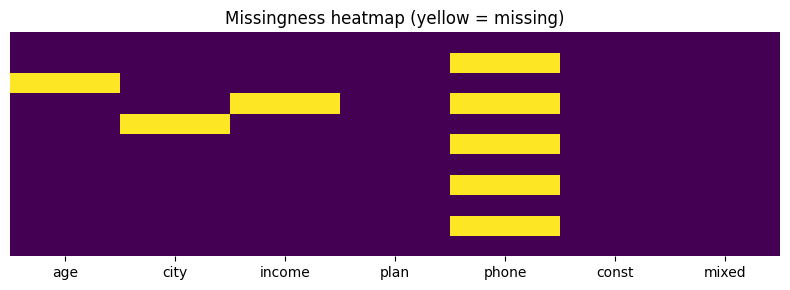

In [22]:
# missing values — table first, then VISUALISE the pattern
print(survey.isna().sum().sort_values(ascending=False))
print("\n% missing:\n", (survey.isna().mean() * 100).round(1))

plt.figure(figsize=(8, 3))
sns.heatmap(survey.isna(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Missingness heatmap (yellow = missing)")
plt.tight_layout()
plt.show()


In [23]:
# how many distinct values per column? constant columns are dead weight
print("nunique:\n", survey.nunique())

constant_cols = survey.columns[survey.nunique() <= 1].tolist()
print("constant columns:", constant_cols)      # -> ['const']

print("\nvalue_counts on categoricals:")
print(survey["city"].value_counts(dropna=False))
print(survey["plan"].value_counts(normalize=True).round(2))   # proportions


nunique:
 age        7
city       6
income     7
plan       2
phone      5
const      1
mixed     10
dtype: int64
constant columns: ['const']

value_counts on categoricals:
city
Delhi      3
Mumbai     2
Pune       2
delhi      1
None       1
pune       1
Kolkata    1
Name: count, dtype: int64
plan
basic    0.55
pro      0.45
Name: proportion, dtype: float64


In [24]:
# mixed types inside one column — classic object-column trap
type_counts = survey["mixed"].apply(type).value_counts()
print(type_counts)
mixed_cols = survey.columns[
    survey.apply(lambda c: c.apply(type).nunique() > 1)
].tolist()
print("columns with mixed python types:", mixed_cols)


mixed
<class 'int'>    9
<class 'str'>    2
Name: count, dtype: int64
columns with mixed python types: ['city', 'phone', 'mixed']


In [25]:
# impossible / out-of-range values (validity checks)
print("age outside [0, 120]:")
print(survey.loc[~survey["age"].between(0, 120) & survey["age"].notna(), ["age"]])
print("\nnegative incomes:", (survey["income"] < 0).sum())
print("city values:", sorted(survey["city"].dropna().unique()))   # -> Delhi/delhi inconsistency


age outside [0, 120]:
     age
6  999.0

negative incomes: 0
city values: ['Delhi', 'Kolkata', 'Mumbai', 'Pune', 'delhi', 'pune']


> **Gotcha:** `survey.info()` only tells you *how many* nulls — not whether
> they cluster in a subgroup (that's a MAR/MNAR question, §6), and never
> tells you about invalid values: `999` is not null, just wrong.

**Section notes — assessment toolkit:**

| Question | Tool |
|---|---|
| shape / types / nulls | `df.shape`, `df.dtypes`, `df.info()` |
| first look | `df.head()`, `df.tail()`, `df.sample(random_state=42)` |
| summary stats | `df.describe()`, `df.describe(include="all")` |
| duplicate rows | `df.duplicated(keep=False)` |
| missingness | `df.isna().sum()`, `sns.heatmap(df.isna())` |
| cardinality | `df.nunique()` |
| category spread | `df[col].value_counts()` |
| dead columns | `df.columns[df.nunique() <= 1]` |
| mixed types | `df[col].apply(type).value_counts()` |
| invalid values | `~df[col].between(lo, hi)` |

---
## 6. Cleaning — missing data

▶ Session 28 - Data Assessing and Cleaning: https://www.youtube.com/watch?v=-HnN8GBINnc
▶ Session on Data Cleaning Case Study - Smartphone dataset: https://www.youtube.com/watch?v=0j_7j3PNSEw

### Why are values missing? (mechanism drives the fix)

| Mechanism | Meaning | Example | Safe fix |
|---|---|---|---|
| **MCAR** — completely at random | missingness unrelated to anything | sensor battery died | drop or impute (both OK) |
| **MAR** — missing at random | depends on *observed* data | older users skip "age" less often | impute using other columns |
| **MNAR** — missing not at random | depends on the missing value itself | high earners hide "income" | model the mechanism / flag it |

### Drop vs impute — strategy table

| Situation | Action |
|---|---|
| tiny fraction missing (<~5%) and rows are plenty | `dropna()` |
| column mostly empty (e.g. >40% missing) | drop the *column* or keep only as a flag |
| numeric, roughly symmetric | mean imputation |
| numeric, **skewed** or with outliers | **median** imputation |
| categorical | mode (most frequent) |
| ordered/time series | `ffill()` / `bfill()` / `interpolate()` |
| you need to *know* it was missing | impute + `SimpleImputer(add_indicator=True)` |
| complex multivariate structure | `KNNImputer` / `IterativeImputer` |

In [26]:
messy = pd.DataFrame({
    "city":   ["Delhi", np.nan, "Mumbai", "Pune", np.nan, "Delhi", "Pune", "Kolkata"],
    "age":    [25.0, 31.0, None, 45.0, 22.0, None, 28.0, 33.0],
    "income": [50000, 60000, 70000, None, 40000, 62000, None, 58000],
})
print("missing per column:\n", messy.isna().sum())
print("rows:", len(messy))


missing per column:
 city      2
age       2
income    2
dtype: int64
rows: 8


In [27]:
# ### `DataFrame.dropna(how="any", thresh=None, subset=None)`
# - `how` — `"any"` (default): drop row if *any* value is NA; `"all"`: only if *all* are NA
# - `thresh` — keep rows with at least N non-NA values
# - `subset` — consider only these columns
# - `axis` — `0` rows (default) or `1` columns
# - `inplace` — mutate (prefer assignment: `df = df.dropna(...)`)
# **Example:**

print("drop any:\n", messy.dropna(how="any"))
print("\ndrop all:\n", messy.dropna(how="all"))
print("\nthresh=2 (keep rows with >=2 values):\n", messy.dropna(thresh=2))
print("\nsubset=['income']:\n", messy.dropna(subset=["income"]))


drop any:
       city   age   income
0    Delhi  25.0  50000.0
7  Kolkata  33.0  58000.0

drop all:
       city   age   income
0    Delhi  25.0  50000.0
1      NaN  31.0  60000.0
2   Mumbai   NaN  70000.0
3     Pune  45.0      NaN
4      NaN  22.0  40000.0
5    Delhi   NaN  62000.0
6     Pune  28.0      NaN
7  Kolkata  33.0  58000.0

thresh=2 (keep rows with >=2 values):
       city   age   income
0    Delhi  25.0  50000.0
1      NaN  31.0  60000.0
2   Mumbai   NaN  70000.0
3     Pune  45.0      NaN
4      NaN  22.0  40000.0
5    Delhi   NaN  62000.0
6     Pune  28.0      NaN
7  Kolkata  33.0  58000.0

subset=['income']:
       city   age   income
0    Delhi  25.0  50000.0
1      NaN  31.0  60000.0
2   Mumbai   NaN  70000.0
4      NaN  22.0  40000.0
5    Delhi   NaN  62000.0
7  Kolkata  33.0  58000.0


In [28]:
# ### `DataFrame.fillna(value)`
# - `value` — scalar, dict per column, or Series/func
# - other methods: `method="ffill"/"bfill"` (prefer `.ffill()` / `.bfill()` in pandas 2.x)
# - `limit` — fill at most N consecutive NaNs
# **Example:**

print(messy.fillna({"city": "Unknown", "age": messy["age"].median(),
                    "income": messy["income"].median()}))


      city   age   income
0    Delhi  25.0  50000.0
1  Unknown  31.0  60000.0
2   Mumbai  29.5  70000.0
3     Pune  45.0  59000.0
4  Unknown  22.0  40000.0
5    Delhi  29.5  62000.0
6     Pune  28.0  59000.0
7  Kolkata  33.0  58000.0


In [29]:
# time series: forward fill, backward fill, interpolation
ts = pd.DataFrame({
    "date":  pd.date_range("2024-01-01", periods=8, freq="D"),
    "sales": [100.0, np.nan, np.nan, 140.0, np.nan, 160.0, 170.0, np.nan],
})
ts["ffill"] = ts["sales"].ffill()             # carry last observation forward
ts["bfill"] = ts["sales"].bfill()             # carry next observation backward
ts["interp"] = ts["sales"].interpolate()      # linear interpolation between points
print(ts)


        date  sales  ffill  bfill      interp
0 2024-01-01  100.0  100.0  100.0  100.000000
1 2024-01-02    NaN  100.0  140.0  113.333333
2 2024-01-03    NaN  100.0  140.0  126.666667
3 2024-01-04  140.0  140.0  140.0  140.000000
4 2024-01-05    NaN  140.0  160.0  150.000000
5 2024-01-06  160.0  160.0  160.0  160.000000
6 2024-01-07  170.0  170.0  170.0  170.000000
7 2024-01-08    NaN  170.0    NaN  170.000000


In [30]:
# ### Stat imputation — mean / median / mode
rng = np.random.default_rng(0)
prices = pd.Series(np.round(rng.lognormal(mean=9.0, sigma=0.7, size=300), 2), name="price")
print("mean  :", round(prices.mean(), 2))
print("median:", round(prices.median(), 2))
# NOTE: lognormal => right-skewed => mean is pulled up by big values => use MEDIAN
print("impute median:", prices.fillna(prices.median()).head(3).tolist())

city_mode = messy["city"].mode()[0]
print("mode of city :", city_mode)
print("filled       :", messy["city"].fillna(city_mode).tolist())


mean  : 10218.38
median: 7680.45
impute median: [8848.57, 7387.37, 12686.53]
mode of city : Delhi
filled       : ['Delhi', 'Delhi', 'Mumbai', 'Pune', 'Delhi', 'Delhi', 'Pune', 'Kolkata']


> **TIP:** mean is only safe when the distribution is roughly symmetric —
> always eyeball the histogram (or check `df.skew()`, §9) before choosing.

In [31]:
# ### `sklearn.impute.SimpleImputer(strategy=..., add_indicator=...)`
# - `strategy` — `"mean"`, `"median"`, `"most_frequent"`, `"constant"`
# - `add_indicator=True` — appends 0/1 columns marking which values were imputed
# - works in pipelines (`fit` on train, `transform` on test → no leakage)
# **Example:**

from sklearn.impute import SimpleImputer, KNNImputer

num = messy[["age", "income"]]

imp_mean = SimpleImputer(strategy="mean")
imp_med = SimpleImputer(strategy="median")
print("mean    :\n", imp_mean.fit_transform(num).round(1))
print("median  :\n", imp_med.fit_transform(num))


mean    :
 [[2.50000e+01 5.00000e+04]
 [3.10000e+01 6.00000e+04]
 [3.07000e+01 7.00000e+04]
 [4.50000e+01 5.66667e+04]
 [2.20000e+01 4.00000e+04]
 [3.07000e+01 6.20000e+04]
 [2.80000e+01 5.66667e+04]
 [3.30000e+01 5.80000e+04]]
median  :
 [[2.50e+01 5.00e+04]
 [3.10e+01 6.00e+04]
 [2.95e+01 7.00e+04]
 [4.50e+01 5.90e+04]
 [2.20e+01 4.00e+04]
 [2.95e+01 6.20e+04]
 [2.80e+01 5.90e+04]
 [3.30e+01 5.80e+04]]


In [32]:
# most_frequent (mode) + constant, and the missing-indicator trick
imp_mode = SimpleImputer(strategy="most_frequent")
print("mode (categorical col):\n", imp_mode.fit_transform(messy[["city"]]))

imp_const = SimpleImputer(strategy="constant", fill_value=-1)
print("constant:\n", imp_const.fit_transform(num)[:3])

imp_flag = SimpleImputer(strategy="median", add_indicator=True)
arr = imp_flag.fit_transform(num)
flag_df = pd.DataFrame(arr, columns=["age", "income", "age_missing", "income_missing"])
print(flag_df)


mode (categorical col):
 [['Delhi']
 ['Delhi']
 ['Mumbai']
 ['Pune']
 ['Delhi']
 ['Delhi']
 ['Pune']
 ['Kolkata']]
constant:
 [[ 2.5e+01  5.0e+04]
 [ 3.1e+01  6.0e+04]
 [-1.0e+00  7.0e+04]]
    age   income  age_missing  income_missing
0  25.0  50000.0          0.0             0.0
1  31.0  60000.0          0.0             0.0
2  29.5  70000.0          1.0             0.0
3  45.0  59000.0          0.0             1.0
4  22.0  40000.0          0.0             0.0
5  29.5  62000.0          1.0             0.0
6  28.0  59000.0          0.0             1.0
7  33.0  58000.0          0.0             0.0


In [33]:
# ### `KNNImputer(n_neighbors=...)` — impute from similar rows
# Finds the k nearest rows (Euclidean distance on observed columns) and averages them.
# (Advanced cousin: `IterativeImputer` — needs
# `from sklearn.experimental import enable_iterative_imputer` first; experimental.)

knn = KNNImputer(n_neighbors=2)
knn_df = pd.DataFrame(knn.fit_transform(num), columns=["age", "income"])
print(knn_df)


    age   income
0  25.0  50000.0
1  31.0  60000.0
2  32.0  70000.0
3  45.0  59000.0
4  22.0  40000.0
5  32.0  62000.0
6  28.0  55000.0
7  33.0  58000.0


### When to drop vs impute — rules of thumb

| Rule of thumb | Choice |
|---|---|
| < 5% of rows affected | drop the rows (or impute — barely matters) |
| a column is > 40-50% missing | drop the column (or keep only the indicator) |
| a row is > 50% missing | drop the row |
| value missing *because* of the outcome (MNAR) | keep an indicator; don't silently impute |
| time series | `ffill` / `interpolate` (order matters!) |
| you will fit ML models | impute **inside the pipeline** (fit on train only) |
| never | fill with a magic number like 0 without thinking (0 may be a real value) |

**Section notes — missing data:**

| Task | Tool |
|---|---|
| drop | `df.dropna(how=, thresh=, subset=)` |
| constant/dict fill | `df.fillna({"col": val})` |
| stats fill | `df.fillna(df["col"].median())` |
| time series | `df.ffill()`, `df.bfill()`, `df.interpolate()` |
| sklearn imputers | `SimpleImputer(strategy=)`, `KNNImputer(k)` |
| remember the holes | `SimpleImputer(add_indicator=True)` |

---
## 7. Cleaning — other issues (dupes, types, strings, outliers, structure)

▶ Session 28 - Data Assessing and Cleaning: https://www.youtube.com/watch?v=-HnN8GBINnc
▶ Session on Data Cleaning Case Study - Smartphone dataset: https://www.youtube.com/watch?v=0j_7j3PNSEw
▶ Session 2 on Data Cleaning - Smartphones Dataset: https://www.youtube.com/watch?v=o-8KvsSdDiE

In [34]:
# ### Duplicates — `duplicated()` / `drop_duplicates()`
dup_demo = pd.DataFrame({
    "sku":   ["A", "B", "A", "C", "B"],
    "qty":   [1, 2, 1, 3, 2],
    "shelf": ["S1", "S2", "S1", "S1", "S2"],
})
print("all rows involved in dupes:\n", dup_demo[dup_demo.duplicated(keep=False)])
print("\nkeep='first':\n", dup_demo.drop_duplicates(keep="first"))
print("\nkeep='last' :", len(dup_demo.drop_duplicates(keep="last")))
print("keep=False  :", len(dup_demo.drop_duplicates(keep=False)))   # drop whole group
print("\non a subset of keys:\n", dup_demo.drop_duplicates(subset=["sku"], keep="first"))
# NOTE: choose keep="first"/"last" deliberately when duplicates carry different payloads


all rows involved in dupes:
   sku  qty shelf
0   A    1    S1
1   B    2    S2
2   A    1    S1
4   B    2    S2

keep='first':
   sku  qty shelf
0   A    1    S1
1   B    2    S2
3   C    3    S1

keep='last' : 3
keep=False  : 1

on a subset of keys:
   sku  qty shelf
0   A    1    S1
1   B    2    S2
3   C    3    S1


In [35]:
# ### Type conversion — `pd.to_datetime(errors="coerce")`
raw_dates = pd.DataFrame({"joined": ["2021-01-05", "05/02/2021", "not a date", "2021-03-08"]})

parsed = pd.to_datetime(raw_dates["joined"], errors="coerce", format="mixed")
raw_dates["joined_dt"] = parsed
print(raw_dates)

bad_rows = raw_dates[parsed.isna()]        # rows that failed to parse
print("\nrows the parser could not understand:\n", bad_rows)
# WARNING: errors="coerce" hides bad data as NaT — always inspect the NaT rows!


       joined  joined_dt
0  2021-01-05 2021-01-05
1  05/02/2021 2021-05-02
2  not a date        NaT
3  2021-03-08 2021-03-08

rows the parser could not understand:
        joined joined_dt
2  not a date       NaT


In [36]:
# numeric conversion with garbage in the column
specs = pd.DataFrame({
    "battery": ["4000mAh", "5000 mAh", "N/A", "4500mAh", "6000MAH"],
    "ram":     ["8 GB", "6GB", "4 GB", "12 GB", " 8 GB "],
    "price":   ["₹12,999", "₹9,999", "₹85,000", "₹1,29,000", "₹15,499"],
})
print(specs)


    battery     ram      price
0   4000mAh    8 GB    ₹12,999
1  5000 mAh     6GB     ₹9,999
2       N/A    4 GB    ₹85,000
3   4500mAh   12 GB  ₹1,29,000
4   6000MAH   8 GB     ₹15,499


In [37]:
# ### String cleaning — `.str.*` + unit extraction
battery = specs["battery"].str.extract(r"(\d+(?:\.\d+)?)")[0].astype(float)   # "4000mAh" -> 4000.0
ram_gb = specs["ram"].str.strip().str.replace(" ", "").str.extract(r"(\d+)")[0].astype(float)
price_inr = (specs["price"]
             .str.replace("₹", "", regex=False)
             .str.replace(",", "", regex=False)
             .astype(float))

clean_specs = pd.DataFrame({
    "battery_mah": battery,
    "ram_gb": ram_gb,
    "price_inr": price_inr,
})
print(clean_specs)
print(clean_specs.dtypes)


   battery_mah  ram_gb  price_inr
0       4000.0     8.0    12999.0
1       5000.0     6.0     9999.0
2          NaN     4.0    85000.0
3       4500.0    12.0   129000.0
4       6000.0     8.0    15499.0
battery_mah    float64
ram_gb         float64
price_inr      float64
dtype: object


In [38]:
# whitespace / case normalisation
messy_brands = pd.Series(["samsung", "Samsung ", "SAMSUNG", "apple",
                          "Apple Inc.", "oneplus", "  poco"])
fixed = (messy_brands
         .str.strip()
         .str.lower()
         .replace({"apple inc.": "apple", "oneplus": "oneplus"})   # consistent labels
         .str.title())                                             # Samsung, Apple, ...
print(pd.DataFrame({"raw": messy_brands, "clean": fixed}))


          raw    clean
0     samsung  Samsung
1    Samsung   Samsung
2     SAMSUNG  Samsung
3       apple    Apple
4  Apple Inc.    Apple
5     oneplus  Oneplus
6        poco     Poco


In [39]:
# ### Unit / scale fixes
weights = pd.DataFrame({"weight": ["1.2 kg", "1200 g", "0.85 kg", "750 g"]})
w = weights["weight"].str.strip()
num = w.str.extract(r"([\d.]+)")[0].astype(float)      # strip the unit first ...
kg = np.where(w.str.endswith("kg"), num, num / 1000)   # ... then scale to kg
weights["weight_kg"] = np.round(kg, 3)
print(weights)


    weight  weight_kg
0   1.2 kg       1.20
1   1200 g       1.20
2  0.85 kg       0.85
3    750 g       0.75


In [40]:
# ### Outliers — IQR (Tukey fences)
income = pd.Series([40000, 42000, 41000, 43000, 45000,
                    44000, 42000, 120000, 46000, 43000], name="income")

q1, q3 = income.quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Q1={q1}, Q3={q3}, IQR={iqr}, fences=[{lo}, {hi}]")
print("outliers:\n", income[(income < lo) | (income > hi)])
print("clipped (np.clip == Series.clip):\n", np.clip(income, lo, hi).tolist())


Q1=42000.0, Q3=44750.0, IQR=2750.0, fences=[37875.0, 48875.0]
outliers:
 7    120000
Name: income, dtype: int64
clipped (np.clip == Series.clip):
 [40000, 42000, 41000, 43000, 45000, 44000, 42000, 48875, 46000, 43000]


z-scores:
 0   -0.43
1   -0.35
2   -0.39
3   -0.31
4   -0.23
5   -0.27
6   -0.35
7    2.84
8   -0.19
9   -0.31
Name: income, dtype: float64
flagged by |z|>3: []
winsorised (top/bottom 10% capped):
 [41000, 42000, 41000, 43000, 45000, 44000, 42000, 46000, 46000, 43000]


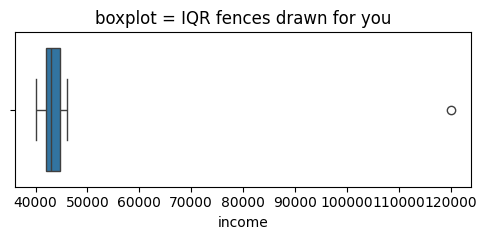

In [41]:
# ### Outliers — z-score (|z| < 3) and the boxplot check
z = (income - income.mean()) / income.std(ddof=1)
print("z-scores:\n", np.round(z, 2))
print("flagged by |z|>3:", income[np.abs(z) >= 3].tolist())
# NOTE: IQR flagged 120000 but |z|<3 did NOT — z-score is weaker on skewed data!

from scipy.stats import mstats
winsorised = pd.Series(mstats.winsorize(income, limits=[0.1, 0.1]), name="winsorised")
print("winsorised (top/bottom 10% capped):\n", winsorised.tolist())

plt.figure(figsize=(5, 2.5))
sns.boxplot(x=income)
plt.title("boxplot = IQR fences drawn for you")
plt.tight_layout()
plt.show()


### Drop vs cap vs transform outliers

| Approach | Code | Use when |
|---|---|---|
| **Drop** | `df[df[col].between(lo, hi)]` | error/contaminated rows you can prove are bad |
| **Cap (winsorise/clip)** | `df[col].clip(lo, hi)`, `mstats.winsorize` | real-but-extreme values, you keep the row |
| **Transform** | `np.log1p(df[col])` | heavy right skew feeding a model |
| **Flag** | `df["is_outlier"] = ~df[col].between(lo, hi)` | you suspect a subgroup (fraud, whales) |
| **Keep** | — | tree models don't care much; EDA should *show* them |

In [42]:
# ### Restructuring — snake_case column names, reorder, drop
def snake_case(name: str) -> str:
    name = name.strip().replace("-", " ").replace("/", " ")
    return "_".join(name.lower().split())

messy_cols = pd.DataFrame([[1, 2, 3, 4]], columns=["First Name", "Join-Date",
                                                   "Annual Salary (INR)", "dept/name"])
print("before:", messy_cols.columns.tolist())
messy_cols.columns = [snake_case(c) for c in messy_cols.columns]
print("after :", messy_cols.columns.tolist())

df_struct = pd.DataFrame({
    "city": ["Delhi", "Pune"],
    "salary": [50000, 60000],
    "notes": ["x", "y"],
    "temp_id": [99, 99],
})
print("\ndrop + reorder:\n",
      df_struct.drop(columns=["temp_id", "notes"])[["salary", "city"]])


before: ['First Name', 'Join-Date', 'Annual Salary (INR)', 'dept/name']
after : ['first_name', 'join_date', 'annual_salary_(inr)', 'dept_name']

drop + reorder:
    salary   city
0   50000  Delhi
1   60000   Pune


In [43]:
# ### Tidy data — wide → long with `melt()`
# Tidy rules: **one variable per column · one observation per row · one table per unit.**
wide = pd.DataFrame({
    "city": ["Delhi", "Mumbai", "Pune"],
    "2022": [10, 20, 15],
    "2023": [12, 25, 18],
})
print("WIDE (years as columns — not tidy):\n", wide)

tidy = wide.melt(id_vars="city", var_name="year", value_name="sales")
tidy["year"] = tidy["year"].astype(int)
print("\nTIDY (one row per city-year):\n", tidy)


WIDE (years as columns — not tidy):
      city  2022  2023
0   Delhi    10    12
1  Mumbai    20    25
2    Pune    15    18

TIDY (one row per city-year):
      city  year  sales
0   Delhi  2022     10
1  Mumbai  2022     20
2    Pune  2022     15
3   Delhi  2023     12
4  Mumbai  2023     25
5    Pune  2023     18


In [44]:
# the reverse: long → wide with pivot
print("\nback to wide:\n", tidy.pivot(index="city", columns="year", values="sales"))



back to wide:
 year    2022  2023
city              
Delhi     10    12
Mumbai    20    25
Pune      15    18


> **Gotcha:** cleaning code must be **re-runnable**: `df = df.drop_duplicates()`,
> never click-and-delete. Keep the raw data read-only and write the cleaned
> result to a new file (e.g. `smartphones_clean.csv`).

**Section notes — cleaning (non-missing):**

| Problem | Tool |
|---|---|
| duplicate rows | `df.duplicated(keep=)`, `df.drop_duplicates()` |
| wrong type | `pd.to_datetime(errors="coerce")`, `pd.to_numeric(errors="coerce")` |
| find bad rows after coerce | `df[parsed.isna()]` |
| units inside strings | `.str.extract(r"(\d+)").astype(float)` |
| messy labels | `.str.strip().str.lower().replace({...}).str.title()` |
| mixed units | `np.where(cond, a, b)` |
| outliers | IQR fences · `clip` · `np.abs(z) < 3` · boxplot |
| ugly names | `snake_case()` rename |
| wide → tidy | `melt(id_vars=, var_name=, value_name=)` |
| tidy → wide | `pivot(index=, columns=, values=)` |

---
## 8. Feature engineering basics

▶ Session 2 on Data Cleaning - Smartphones Dataset: https://www.youtube.com/watch?v=o-8KvsSdDiE

Feature engineering = creating model/analysis-friendly columns from raw ones.
Done **after** cleaning, **before** modelling (and often during EDA too).

In [45]:
# ### Derived columns — from dates and numbers
fe = pd.DataFrame({
    "order_date": pd.date_range("2024-01-05", periods=8, freq="5D"),
    "price": [499.5, 1299.0, 79.0, 4999.0, 199.0, 2500.0, 799.0, 15000.0],
})
fe["year"] = fe["order_date"].dt.year
fe["month"] = fe["order_date"].dt.month
fe["day_name"] = fe["order_date"].dt.day_name()
fe["is_weekend"] = fe["day_name"].isin(["Saturday", "Sunday"])
fe["log_price"] = np.log1p(fe["price"])       # log1p == log(1+x), safe for 0
fe["price_bucket"] = pd.cut(
    fe["price"], bins=[0, 500, 2000, np.inf],
    labels=["cheap", "mid", "premium"],
)
print(fe)


  order_date    price  year  month   day_name  is_weekend  log_price  \
0 2024-01-05    499.5  2024      1     Friday       False   6.215608   
1 2024-01-10   1299.0  2024      1  Wednesday       False   7.170120   
2 2024-01-15     79.0  2024      1     Monday       False   4.382027   
3 2024-01-20   4999.0  2024      1   Saturday        True   8.517193   
4 2024-01-25    199.0  2024      1   Thursday       False   5.298317   
5 2024-01-30   2500.0  2024      1    Tuesday       False   7.824446   
6 2024-02-04    799.0  2024      2     Sunday        True   6.684612   
7 2024-02-09  15000.0  2024      2     Friday       False   9.615872   

  price_bucket  
0        cheap  
1          mid  
2        cheap  
3      premium  
4        cheap  
5      premium  
6          mid  
7      premium  


In [46]:
# ### Binning — `pd.cut` (equal width) vs `pd.qcut` (equal frequency)
values = [5, 10, 12, 15, 18, 20, 22, 25, 40, 95]
print("cut   :", pd.cut(values, bins=3, labels=["low", "mid", "high"]).tolist())
print("qcut  :", pd.qcut(values, q=3, labels=["low", "mid", "high"]).tolist())
# cut -> equal *ranges* (may give unbalanced bins) ; qcut -> equal *counts*


cut   : ['low', 'low', 'low', 'low', 'low', 'low', 'low', 'low', 'mid', 'high']
qcut  : ['low', 'low', 'low', 'mid', 'mid', 'mid', 'high', 'high', 'high', 'high']


In [47]:
# ### Encoding basics
enc = pd.DataFrame({
    "city": ["Delhi", "Mumbai", "Pune", "Delhi"],
    "plan": ["basic", "pro", "premium", "pro"],
})
print(pd.get_dummies(enc["city"], prefix="city", dtype=int))       # one-hot

ordinal = {"basic": 1, "pro": 2, "premium": 3}
print(enc["plan"].map(ordinal))                                    # ordinal mapping


   city_Delhi  city_Mumbai  city_Pune
0           1            0          0
1           0            1          0
2           0            0          1
3           1            0          0
0    1
1    2
2    3
3    2
Name: plan, dtype: int64


### Encoding — when to use which

| Encoding | Example | Use when | Avoid when |
|---|---|---|---|
| one-hot (`get_dummies`) | `city_Delhi, city_Pune` | nominal, few categories (<~15), linear models | high cardinality (city 500+) |
| ordinal `map` | `basic=1, pro=2` | categories have a real order | the order is arbitrary |
| target encoding | mean of target per category | high cardinality (needs CV to avoid leakage) | tiny categories |
| frequency / count | `value_counts()` map | instead of one-hot for high cardinality | you need interpretability |
| drop | — | constant or ID column | never drop a genuinely predictive feature |

> **Gotcha:** fit encodings **on train, apply to test** (`OrdinalEncoder(handle_unknown="use_encoded_value")`)
> — `get_dummies` on the full data leaks the test set's category list.

**Section notes — feature engineering:**

| Goal | Code |
|---|---|
| date parts | `df["date"].dt.year / .dt.month / .dt.day_name()` |
| log scale | `np.log1p(df["price"])` |
| equal-width bins | `pd.cut(x, bins=, labels=)` |
| equal-freq bins | `pd.qcut(x, q=, labels=)` |
| one-hot | `pd.get_dummies(col, prefix=, dtype=int)` |
| ordinal | `col.map({"a": 1, "b": 2})` |

---
## 9. EDA — Exploratory Data Analysis

▶ Session 29 - Exploratory Data Analysis: https://www.youtube.com/watch?v=PPEHpg2RixQ

EDA = let the data speak **before** any modelling: distributions,
relationships, groups, anomalies. Guided by hypothesis, shown with charts.

In [48]:
rng = np.random.default_rng(7)
exp = rng.integers(0, 15, size=80)
eda = pd.DataFrame({
    "experience": exp,
    "age": 22 + exp + rng.integers(0, 8, size=80),
    "salary": 300000 + 35000 * exp + rng.normal(0, 60000, size=80).round(-3),
    "department": rng.choice(["IT", "HR", "Finance", "Sales"], size=80),
    "city": rng.choice(["Delhi", "Mumbai", "Pune", "Kolkata"], size=80),
})
print(eda.head())


   experience  age    salary department    city
0          14   40  881000.0         HR  Mumbai
1           9   33  589000.0      Sales    Pune
2          10   39  632000.0      Sales   Delhi
3          13   42  776000.0      Sales    Pune
4           8   31  573000.0    Finance   Delhi


### Univariate analysis — one variable at a time
| Variable type | Numbers | Chart |
|---|---|---|
| numeric | `describe()` | histogram + KDE, boxplot |
| categorical | `value_counts()` | bar / countplot |

       experience        age         salary
count   80.000000  80.000000      80.000000
mean     7.387500  32.975000  550487.500000
std      4.425169   5.121251  165892.751213
min      0.000000  22.000000  172000.000000
25%      3.750000  29.750000  423500.000000
50%      7.000000  32.500000  567500.000000
75%     12.000000  37.250000  658000.000000
max     14.000000  42.000000  881000.000000


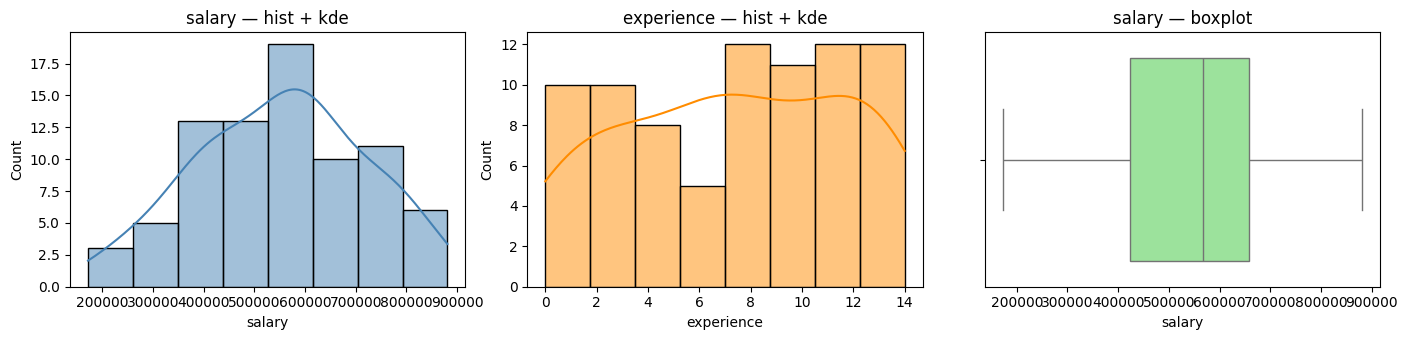

In [49]:
# numeric
print(eda[["experience", "age", "salary"]].describe())

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
sns.histplot(eda["salary"], kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("salary — hist + kde")
sns.histplot(eda["experience"], kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("experience — hist + kde")
sns.boxplot(x=eda["salary"], ax=axes[2], color="lightgreen")
axes[2].set_title("salary — boxplot")
plt.tight_layout()
plt.show()


department
Sales      22
IT         22
Finance    21
HR         15
Name: count, dtype: int64

normalized:
 department
Sales      0.275
IT         0.275
Finance    0.262
HR         0.188
Name: proportion, dtype: float64


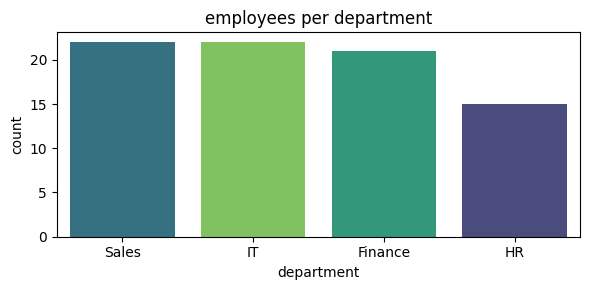

In [50]:
# categorical
print(eda["department"].value_counts())
print("\nnormalized:\n", eda["department"].value_counts(normalize=True).round(3))

plt.figure(figsize=(6, 3))
sns.countplot(x=eda["department"], order=eda["department"].value_counts().index,
              hue=eda["department"], palette="viridis", legend=False)
plt.title("employees per department")
plt.tight_layout()
plt.show()


### Bivariate analysis — two variables together
| Pair | Numeric-numeric | Numeric-categorical | Categorical-categorical |
|---|---|---|---|
| Tool | `scatter`, `corr` | `boxplot`/`groupby.mean` | `crosstab`/`countplot(hue)` |

            experience       age    salary
experience    1.000000  0.905294  0.945886
age           0.905294  1.000000  0.832475
salary        0.945886  0.832475  1.000000


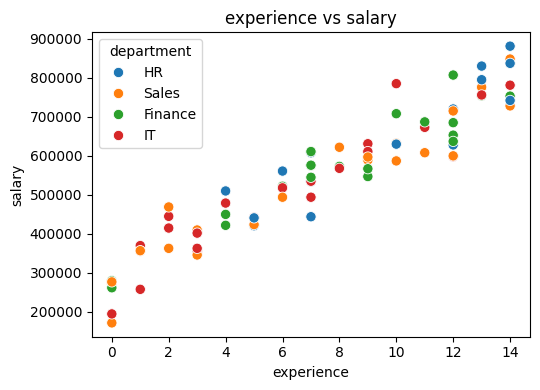

In [51]:
# numeric vs numeric: scatter + correlation
print(eda[["experience", "age", "salary"]].corr())

plt.figure(figsize=(5.5, 4))
sns.scatterplot(data=eda, x="experience", y="salary", hue="department", s=55)
plt.title("experience vs salary")
plt.tight_layout()
plt.show()


            count           mean    median
department                                
Finance        21  572285.714286  575000.0
HR             15  638800.000000  628000.0
IT             22  508909.090909  506000.0
Sales          22  511045.454545  540500.0


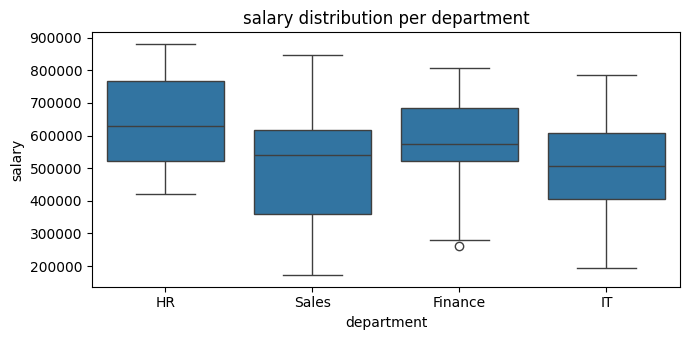

In [52]:
# numeric vs categorical: group summaries + boxplot
print(eda.groupby("department")["salary"].agg(["count", "mean", "median"]))

plt.figure(figsize=(7, 3.5))
sns.boxplot(data=eda, x="department", y="salary")
plt.title("salary distribution per department")
plt.tight_layout()
plt.show()


### Multivariate analysis — several variables at once

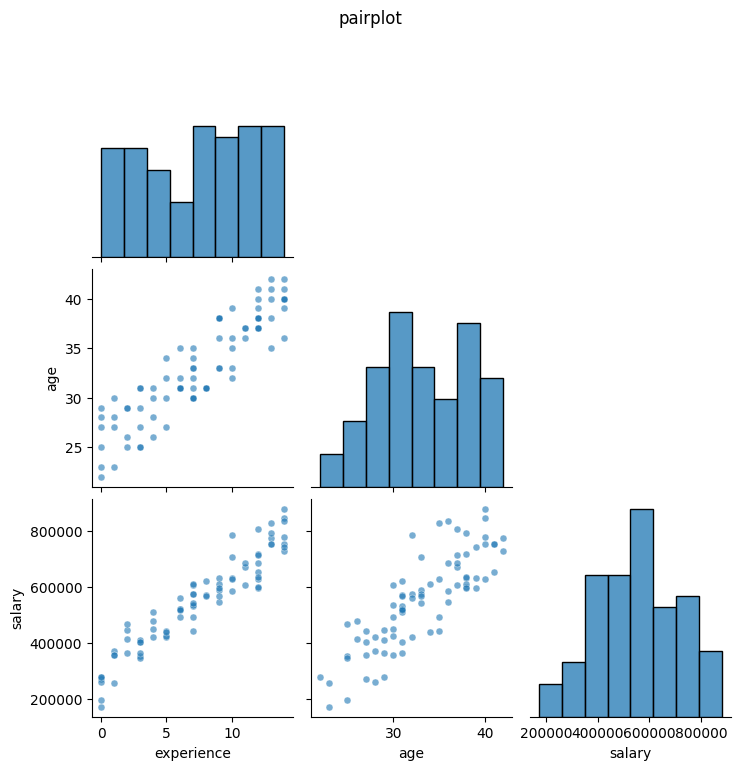

In [53]:
sns.pairplot(eda[["experience", "age", "salary"]], corner=True,
             plot_kws={"s": 25, "alpha": 0.6})
plt.suptitle("pairplot", y=1.02)
plt.show()


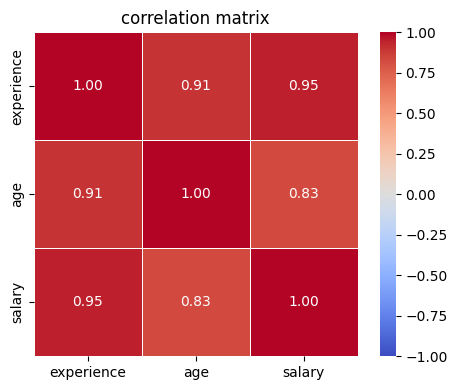

In [54]:
# annotated correlation heatmap (numbers written inside the cells)
corr = eda[["experience", "age", "salary"]].corr()
plt.figure(figsize=(5, 4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.5)
plt.title("correlation matrix")
plt.tight_layout()
plt.show()


city           Delhi   Kolkata    Mumbai      Pune
department                                        
Finance     619333.0  525500.0  523750.0  610800.0
HR          552250.0  669400.0  679200.0  630000.0
IT          403333.0  552800.0  619000.0  459600.0
Sales       499000.0  641800.0  484667.0  447143.0


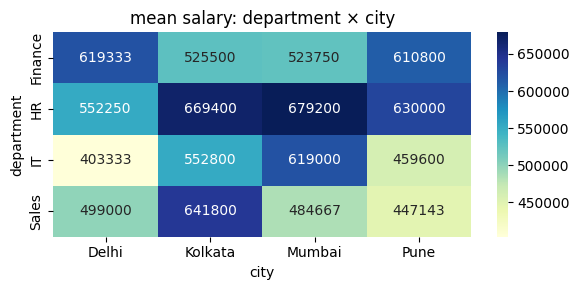

In [55]:
# pivot_table heatmap — group means in colour
pivot = pd.pivot_table(eda, index="department", columns="city",
                       values="salary", aggfunc="mean")
print(pivot.round(0))

plt.figure(figsize=(6, 3))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("mean salary: department × city")
plt.tight_layout()
plt.show()


### Correlation ≠ causation
`salary` and `age` correlate because both rise with `experience` — age does not
*cause* salary to grow. A real causal claim needs a design (experiment,
natural experiment, or a defensible identification strategy), not a heatmap.
Spurious classic: "US cheese sales ↔ deaths by tangled bedsheets".

### Pearson vs Spearman

| | Pearson `r` | Spearman `ρ` |
|---|---|---|
| measures | **linear** relationship | **monotonic** relationship (any shape) |
| input | raw values | ranks of the values |
| robust to outliers | ❌ | ✅ |
| needs normality | roughly | no |

In [56]:
from scipy.stats import pearsonr, spearmanr

r_p, p_p = pearsonr(eda["experience"], eda["salary"])
r_s, p_s = spearmanr(eda["experience"], eda["salary"])
print(f"Pearson  r = {r_p:.3f}  (p = {p_p:.2e})")
print(f"Spearman r = {r_s:.3f}  (p = {p_s:.2e})")

# a non-linear monotonic relationship where the two disagree:
x = np.arange(1, 21, dtype=float)
y = np.exp(x / 6) + np.array([0.0, 0.4, -0.3] * 7)[:20]
print("\nexp relationship -> Pearson :", round(pearsonr(x, y)[0], 3),
      "| Spearman:", round(spearmanr(x, y)[0], 3))


Pearson  r = 0.946  (p = 7.12e-40)
Spearman r = 0.954  (p = 1.17e-42)

exp relationship -> Pearson : 0.922 | Spearman: 0.995


In [57]:
# ### Skewness & kurtosis
print("skew  (0 = symmetric, >0 = right tail):\n", eda[["salary", "experience"]].skew().round(3))
print("\nkurtosis (0 = normal-like, >0 = heavy tails) [Fisher definition]:\n",
      eda[["salary", "experience"]].kurt().round(3))


skew  (0 = symmetric, >0 = right tail):
 salary       -0.129
experience   -0.115
dtype: float64

kurtosis (0 = normal-like, >0 = heavy tails) [Fisher definition]:
 salary       -0.586
experience   -1.194
dtype: float64


In [58]:
# ### Outliers distort mean vs median — see it directly
incomes = pd.Series([42000, 43000, 41000, 44000, 45000, 420000], name="income")
print("with outlier   -> mean:", incomes.mean(), "| median:", incomes.median())
print("without outlier-> mean:", incomes[:-1].mean(), "| median:", incomes[:-1].median())
# NOTE: the mean jumped 4-5x, the median barely moved — always report BOTH.


with outlier   -> mean: 105833.33333333333 | median: 43500.0
without outlier-> mean: 43000.0 | median: 43000.0


### EDA checklist — 30 questions to ask of ANY dataset

| # | Question | Tool |
|---|---|---|
| 1 | How many rows and columns? | `df.shape` |
| 2 | What does one row represent? | `df.head()` |
| 3 | Which columns are identifiers? | `df.nunique()` ≈ `len(df)` |
| 4 | What are the dtypes? | `df.dtypes` / `df.info()` |
| 5 | How many missing values per column? | `df.isna().sum()` |
| 6 | Are missingness concentrated in a subgroup? | heatmap + `groupby` on missing flag |
| 7 | Are there duplicate rows/keys? | `df.duplicated()` |
| 8 | Constant columns? | `df.nunique() <= 1` |
| 9 | Mixed types in a column? | `apply(type).value_counts()` |
| 10 | Impossible values (age 999, negative price)? | range checks |
| 11 | Category labels inconsistent (case/typos)? | `value_counts()` |
| 12 | Units consistent (kg vs g, ₹ vs k)? | `.str.extract`, `unique()` |
| 13 | What are min/max/mean/median of numerics? | `describe()` |
| 14 | Are the distributions skewed? | `skew()`, hist |
| 15 | Heavy tails / outliers? | boxplot, IQR |
| 16 | Any zero-inflation / constants? | `value_counts()` head |
| 17 | Top categories and their share? | `value_counts(normalize=True)` |
| 18 | Which numeric pairs are correlated? | `corr()` + heatmap |
| 19 | Any near-perfect (deterministic) pairs? | `\|r\| > 0.99` → multicollinearity |
| 20 | Do groups differ (dept × salary)? | `groupby.mean()`, boxplot |
| 21 | Interaction visible (2 factors × 1 metric)? | `pivot_table` + heatmap |
| 22 | Any trend over time? | `groupby(pd.Grouper(freq="M"))` plot |
| 23 | Seasonality (weekday/month effects)? | `dt.day_name()` groupby |
| 24 | Does the target leak into features? | correlation with target |
| 25 | Class balance (classification)? | `value_counts(normalize=True)` |
| 26 | Train/test split feasible? | row count per group/time |
| 27 | Which rows are most unlike the rest? | z-score / isolation forest |
| 28 | Which single feature would I show a stakeholder first? | domain knowledge |
| 29 | What is the ONE number that matters? | the business metric |
| 30 | What can this data NOT answer? | scope limits (write them down) |

**Section notes — EDA:**

| Level | Tools |
|---|---|
| univariate | `describe()`, `histplot(kde=True)`, `boxplot`, `value_counts`, `countplot` |
| bivariate | `scatterplot`, `corr()`, `boxplot(by group)`, `groupby.mean()`, `crosstab` |
| multivariate | `pairplot`, annotated `heatmap`, `pivot_table` + `heatmap` |
| statistics | `pearsonr`/`spearmanr`, `skew()`, `kurt()`, mean vs median |

---
## 10. End-to-end case study — messy smartphone dataset

▶ Session on Data Cleaning Case Study - Smartphone dataset: https://www.youtube.com/watch?v=0j_7j3PNSEw
▶ Session 2 on Data Cleaning - Smartphones Dataset: https://www.youtube.com/watch?v=o-8KvsSdDiE
▶ Session on EDA Case Study - Smartphones Dataset: https://www.youtube.com/watch?v=PxRth8xosqY

Build → assess → clean → EDA → insights, exactly like the sessions.

In [59]:
# STEP 0 — the RAW dataset (as scraped / exported; nothing cleaned, on purpose)
phones = pd.DataFrame({
    "name":     ["Galaxy S21", "iPhone 13", "Redmi Note 10", "Galaxy S21", "Pixel 6",
                 "Nord CE", "iPhone 12", "Moto G60", "Realme 8", "Galaxy A52", "Poco X3"],
    "brand":    ["samsung", "Apple", "Xiaomi", "samsung", "GOOGLE",
                 "oneplus", None, "Motorola", "realme", "Samsung", "POCO"],
    "ratings":  ["4.5★", "4.6★", "4.3★", "4.5★", "4.4★",
                 "4.2★", "4.5★", "N/A", "4.1★", "4.3★", "4.4★"],
    "ram":      ["8 GB", "4 GB", "6 GB", "8 GB", "8 GB",
                 "6 GB", "4 GB", "6 GB", None, "8 GB", "6 GB"],
    "price":    ["₹49,999", "₹79,900", "₹13,999", "₹49,999", "₹44,999",
                 "₹24,999", "₹54,900", "₹17,999", "₹15,999", "₹34,999", "₹16,999"],
    "battery":  ["4000mAh", "3240mAh", "5000mAh", "4000mAh", "4614mAh",
                 "4500mAh", None, "6000mAh", "5000mAh", "4500mAh", "6000 mAh"],
    "released": ["2021-01-14", "2021-09-24", "2021-03-16", "2021-01-14", "2021-10-28",
                 "2021-06-10", "2020-10-23", "2021-10-01", "2021-03-25", "2021-03-26",
                 "2021-09-30"],
})
print("raw shape:", phones.shape)
phones


raw shape: (11, 7)


,name,brand,ratings,ram,price,battery,released
0,Galaxy S21,samsung,4.5★,8 GB,"₹49,999",4000mAh,2021-01-14
1,iPhone 13,Apple,4.6★,4 GB,"₹79,900",3240mAh,2021-09-24
2,Redmi Note 10,Xiaomi,4.3★,6 GB,"₹13,999",5000mAh,2021-03-16
3,Galaxy S21,samsung,4.5★,8 GB,"₹49,999",4000mAh,2021-01-14
4,Pixel 6,GOOGLE,4.4★,8 GB,"₹44,999",4614mAh,2021-10-28
5,Nord CE,oneplus,4.2★,6 GB,"₹24,999",4500mAh,2021-06-10
6,iPhone 12,None,4.5★,4 GB,"₹54,900",None,2020-10-23
7,Moto G60,Motorola,N/A,6 GB,"₹17,999",6000mAh,2021-10-01
8,Realme 8,realme,4.1★,None,"₹15,999",5000mAh,2021-03-25
9,Galaxy A52,Samsung,4.3★,8 GB,"₹34,999",4500mAh,2021-03-26


### Assessing — the problems found (read-only pass)

1. **Duplicate row** — `Galaxy S21` appears twice with identical values (rows 0 & 3).
2. **Missing values** — `brand` (iPhone 12), `ram` (Realme 8), `battery` (iPhone 12).
3. **Inconsistent categorical casing** — `samsung`/`Samsung`, `GOOGLE`, `oneplus`, `POCO`, `realme`.
4. **Rating trapped in a string + junk value** — `"4.5★"`, and `"N/A"` (not numeric).
5. **Unit embedded in numbers** — `ram` = `"8 GB"`, `battery` = `"4000mAh"` / `"6000 mAh"` (space varies).
6. **Currency & thousands separator** — `price` = `"₹49,999"` (₹ sign + commas).
7. **Dates are strings** — `released` is `object`, not `datetime64`.

...and the code that proves each one:

In [60]:
print("1. duplicates:", phones.duplicated().sum(),
      "-> rows:", phones.index[phones.duplicated(keep=False)].tolist())
print("2. missing:\n", phones.isna().sum()[phones.isna().sum() > 0])
print("3. brand labels:", sorted(phones["brand"].dropna().unique()))
print("4. ratings uniques:", phones["ratings"].unique())
print("5. ram uniques:", phones["ram"].unique())
print("6. price sample:", phones["price"].iloc[0])
print("7. dtypes:\n", phones.dtypes)


1. duplicates: 1 -> rows: [0, 3]
2. missing:
 brand      1
ram        1
battery    1
dtype: int64
3. brand labels: ['Apple', 'GOOGLE', 'Motorola', 'POCO', 'Samsung', 'Xiaomi', 'oneplus', 'realme', 'samsung']
4. ratings uniques: ['4.5★' '4.6★' '4.3★' '4.4★' '4.2★' 'N/A' '4.1★']
5. ram uniques: ['8 GB' '4 GB' '6 GB' None]
6. price sample: ₹49,999
7. dtypes:
 name        object
brand       object
ratings     object
ram         object
price       object
battery     object
released    object
dtype: object


### Cleaning — step by step

In [61]:
# STEP 1 — drop exact duplicates (row 3 goes away -> 10 rows)
clean = phones.drop_duplicates().copy()
print("after drop_duplicates:", clean.shape)


after drop_duplicates: (10, 7)


In [62]:
# STEP 2 — standardise the categorical `brand`
clean["brand"] = (clean["brand"]
                  .str.strip()
                  .str.lower()
                  .replace({"google": "Google", "oneplus": "OnePlus", "poco": "Poco"})
                  .str.title())
# fill the one missing brand from the product name
clean.loc[clean["brand"].isna() & clean["name"].str.contains("iPhone"), "brand"] = "Apple"
print(clean["brand"].value_counts())


brand
Samsung     2
Apple       2
Xiaomi      1
Google      1
Oneplus     1
Motorola    1
Realme      1
Poco        1
Name: count, dtype: int64


In [63]:
# STEP 3 — extract numerics from strings ("4.5★" -> 4.5, "8 GB" -> 8, "₹49,999" -> 49999)
clean["rating"] = (clean["ratings"]
                   .str.extract(r"(\d+\.\d+)")
                   .astype(float))                       # "N/A" -> NaN (coerced)
clean["ram_gb"] = clean["ram"].str.extract(r"(\d+)")[0].astype(float)
clean["battery_ma"] = clean["battery"].str.extract(r"(\d+)")[0].astype(float)
clean["price_inr"] = (clean["price"]
                      .str.replace("₹", "", regex=False)
                      .str.replace(",", "", regex=False)
                      .astype(float))
print(clean[["name", "rating", "ram_gb", "battery_ma", "price_inr"]])


             name  rating  ram_gb  battery_ma  price_inr
0      Galaxy S21     4.5     8.0      4000.0    49999.0
1       iPhone 13     4.6     4.0      3240.0    79900.0
2   Redmi Note 10     4.3     6.0      5000.0    13999.0
4         Pixel 6     4.4     8.0      4614.0    44999.0
5         Nord CE     4.2     6.0      4500.0    24999.0
6       iPhone 12     4.5     4.0         NaN    54900.0
7        Moto G60     NaN     6.0      6000.0    17999.0
8        Realme 8     4.1     NaN      5000.0    15999.0
9      Galaxy A52     4.3     8.0      4500.0    34999.0
10        Poco X3     4.4     6.0      6000.0    16999.0


In [64]:
# STEP 4 — handle the remaining missing numerics + parse dates
clean["rating"] = clean["rating"].fillna(clean["rating"].median())
clean["ram_gb"] = clean["ram_gb"].fillna(clean["ram_gb"].median())
clean["battery_ma"] = clean["battery_ma"].fillna(clean["battery_ma"].median())
clean["released_dt"] = pd.to_datetime(clean["released"], errors="coerce")
print("still missing after imputation:\n", clean.isna().sum()[clean.isna().sum() > 0])


still missing after imputation:
 ram        1
battery    1
dtype: int64


In [65]:
# STEP 5 — final tidy frame: keep only analysis columns, ordered
phones_clean = (clean
                .drop(columns=["ratings", "ram", "battery", "price", "released"])
                .rename(columns={"name": "model"})
                .sort_values("price_inr", ascending=False)
                .reset_index(drop=True))
phones_clean["year"] = phones_clean["released_dt"].dt.year.astype(int)
phones_clean["ram_gb"] = phones_clean["ram_gb"].astype(int)
phones_clean["battery_ma"] = phones_clean["battery_ma"].astype(int)
phones_clean["price_inr"] = phones_clean["price_inr"].astype(int)
print(phones_clean.dtypes)
phones_clean


model                  object
brand                  object
rating                float64
ram_gb                  int64
battery_ma              int64
price_inr               int64
released_dt    datetime64[ns]
year                    int64
dtype: object


,model,brand,rating,ram_gb,battery_ma,price_inr,released_dt,year
0,iPhone 13,Apple,4.6,4,3240,79900,2021-09-24,2021
1,iPhone 12,Apple,4.5,4,4614,54900,2020-10-23,2020
2,Galaxy S21,Samsung,4.5,8,4000,49999,2021-01-14,2021
3,Pixel 6,Google,4.4,8,4614,44999,2021-10-28,2021
4,Galaxy A52,Samsung,4.3,8,4500,34999,2021-03-26,2021
5,Nord CE,Oneplus,4.2,6,4500,24999,2021-06-10,2021
6,Moto G60,Motorola,4.4,6,6000,17999,2021-10-01,2021
7,Poco X3,Poco,4.4,6,6000,16999,2021-09-30,2021
8,Realme 8,Realme,4.1,6,5000,15999,2021-03-25,2021
9,Redmi Note 10,Xiaomi,4.3,6,5000,13999,2021-03-16,2021


### EDA on the cleaned data

       price_inr  ram_gb  battery_ma  rating
count      10.00   10.00       10.00   10.00
mean    35479.20    6.20     4746.80    4.37
std     21730.28    1.48      833.63    0.15
min     13999.00    4.00     3240.00    4.10
25%     17249.00    6.00     4500.00    4.30
50%     29999.00    6.00     4614.00    4.40
75%     48749.00    7.50     5000.00    4.47
max     79900.00    8.00     6000.00    4.60

median price : 29999.0
brands        : 8


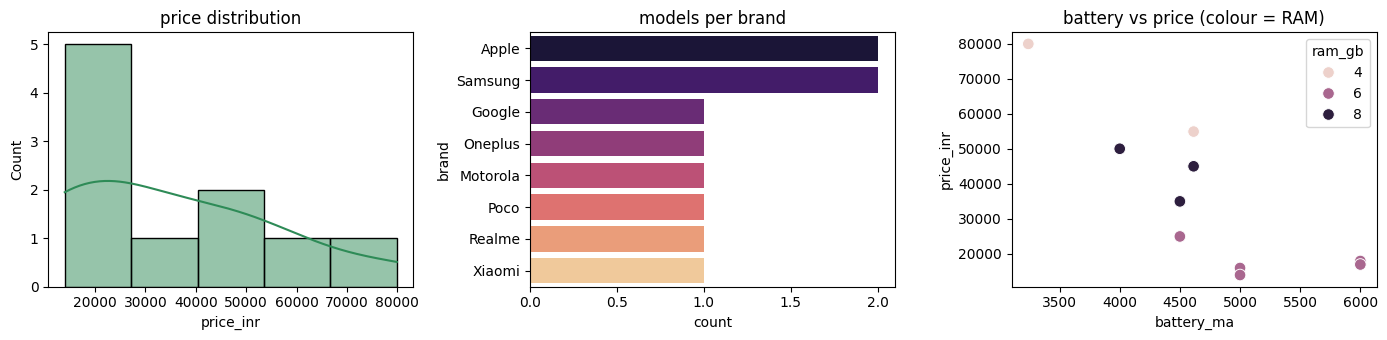

In [66]:
# univariate — numbers
print(phones_clean[["price_inr", "ram_gb", "battery_ma", "rating"]].describe().round(2))
print("\nmedian price :", phones_clean["price_inr"].median())
print("brands        :", phones_clean["brand"].nunique())

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
sns.histplot(phones_clean["price_inr"], kde=True, ax=axes[0], color="seagreen")
axes[0].set_title("price distribution")
sns.countplot(y=phones_clean["brand"], order=phones_clean["brand"].value_counts().index,
              hue=phones_clean["brand"], palette="magma", ax=axes[1], legend=False)
axes[1].set_title("models per brand")
sns.scatterplot(data=phones_clean, x="battery_ma", y="price_inr",
                hue="ram_gb", ax=axes[2], s=70)
axes[2].set_title("battery vs price (colour = RAM)")
plt.tight_layout()
plt.show()


            rating  ram_gb  battery_ma  price_inr
rating        1.00   -0.27       -0.37       0.77
ram_gb       -0.27    1.00        0.09      -0.28
battery_ma   -0.37    0.09        1.00      -0.82
price_inr     0.77   -0.28       -0.82       1.00


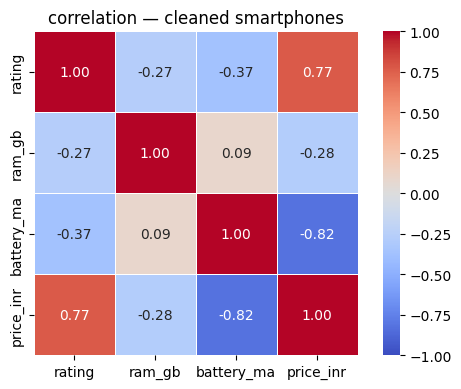


brand group summary:
          models  avg_price  avg_rating  avg_battery
brand                                               
Apple          2    67400.0         4.6       3927.0
Google         1    44999.0         4.4       4614.0
Samsung        2    42499.0         4.4       4250.0
Oneplus        1    24999.0         4.2       4500.0
Motorola       1    17999.0         4.4       6000.0
Poco           1    16999.0         4.4       6000.0
Realme         1    15999.0         4.1       5000.0
Xiaomi         1    13999.0         4.3       5000.0


In [67]:
# bivariate — correlation + group insights
num_cols = phones_clean[["rating", "ram_gb", "battery_ma", "price_inr"]]
corr = num_cols.corr()
print(corr.round(2))

plt.figure(figsize=(5.5, 4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.5)
plt.title("correlation — cleaned smartphones")
plt.tight_layout()
plt.show()

print("\nbrand group summary:")
print(phones_clean.groupby("brand").agg(
    models=("model", "count"),
    avg_price=("price_inr", "mean"),
    avg_rating=("rating", "mean"),
    avg_battery=("battery_ma", "mean"),
).round(1).sort_values("avg_price", ascending=False))


### Insights — 5 findings from this dataset

1. **Cleaning cost ~40% of the work:** 11 raw rows → 10 after dropping one exact
   duplicate; 4 numeric columns (`ratings`, `ram`, `price`, `battery`) held text
   like `"₹49,999"`, `"4.5★"`, `"4000mAh"` and needed regex extraction before any
   statistic was possible, plus `released` had to be parsed into real dates.
2. **Price separates into two clear tiers** — budget models (~₹14k) and flagships
   (~₹80k) differ by more than 5×. Price correlates strongly *positively* with
   `rating` (+0.77) and strongly *negatively* with `battery_ma` (−0.82: giant
   batteries are the signature of budget phones), while `ram_gb` is only weakly
   related (−0.28).
3. **Apple/Samsung anchor the top of the price band**, while Xiaomi, Poco, Realme
   and Motorola cluster in the budget segment (see `groupby("brand")` table above).
4. **`"N/A"` in ratings was a *validity* issue, not a missing-value one** — coercion
   to `NaN` and median imputation changed Moto G60's rating; a flag column would
   let a model treat it differently.
5. **Dates opened a second feature for free:** parsing `released` gave a release
   `year` (2020-2021 cohort) — an example of feature engineering done *during* EDA.

> **Take-away:** assess first (write the problem list down), clean with code
> (never by hand), then explore — the EDA above only became possible because
> every column was numeric, unique-keyed and duplicate-free.

---
## Quick revision sheet

| Problem | pandas / sklearn tool |
|---|---|
| read a CSV | `pd.read_csv(path, sep=, encoding=, usecols=, nrows=, dtype=, parse_dates=, na_values=)` |
| read Excel | `pd.read_excel(path, sheet_name=, engine="openpyxl")` |
| read JSON | `pd.read_json(buf, orient=, lines=)` |
| read SQL | `pd.read_sql_query(sql, con)` |
| CSV from a string | `pd.read_csv(StringIO(text))` |
| call a REST API | `requests.get(url, params=, headers=, timeout=3).json()` + try/except fallback |
| scrape HTML | `BeautifulSoup(html, "html.parser").find_all(...)` |
| first look | `head/tail/sample(random_state)/info/describe(include="all")/shape/dtypes` |
| duplicates | `duplicated(keep=False)` → `drop_duplicates()` |
| missing counts | `isna().sum()` + `sns.heatmap(df.isna())` |
| constant / mixed columns | `nunique() <= 1`, `apply(type).value_counts()` |
| invalid range | `~df[c].between(lo, hi)` |
| drop missing | `dropna(how=, thresh=, subset=)` |
| fill missing | `fillna(value)` / `.ffill()` / `.bfill()` / `.interpolate()` |
| impute with stats | `SimpleImputer(strategy="median"/"most_frequent", add_indicator=True)` |
| impute smartly | `KNNImputer(n_neighbors=)` |
| parse dates safely | `pd.to_datetime(errors="coerce")` + inspect `NaT` rows |
| extract units | `.str.extract(r"(\d+)").astype(float)` |
| fix label mess | `.str.strip().str.lower().replace({...}).str.title()` |
| outliers | IQR fences · `clip(lo, hi)` · `np.abs(z) < 3` · boxplot |
| snake_case names | rename with a `snake_case()` helper |
| tidy wide → long | `melt(id_vars=, var_name=, value_name=)` |
| date features | `.dt.year / .dt.month / .dt.day_name()` |
| log transform | `np.log1p(x)` |
| binning | `pd.cut(bins=)`, `pd.qcut(q=)` |
| encoding | `get_dummies` (nominal) · `.map()` (ordinal) |
| univariate | `describe`, `histplot(kde=True)`, `boxplot`, `value_counts` |
| bivariate | `scatterplot`, `corr`, `boxplot(by)`, `groupby.mean()` |
| multivariate | `pairplot`, annotated `heatmap`, `pivot_table` |
| linear vs monotonic | `pearsonr` vs `spearmanr` |

> **Interview short-list:** assess *before* you clean · MCAR/MAR/MNAR ·
> median for skewed data · `errors="coerce"` hides bad rows (inspect them!) ·
> IQR vs z-score for outliers · tidy data rules · correlation ≠ causation ·
> never overwrite raw data.

---
**Next notebook:** `07_sql.ipynb` — gathering and cleaning data straight from
the source with SQL (runnable via `sqlite3`).

**Playlist:** https://www.youtube.com/playlist?list=PLKnIA16_RmvbAlyx4_rdtR66B7EHX5k3z